In [1]:
%pip install tensorflow opencv-python

  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.85.1-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached keras_nightly-3.16.0.dev2026103103-py3-none-any.whl.metadata (6.6 kB)
  Using cached h5py-3.15.1-cp314-cp314-win_amd64.whl.metadata (3.1 kB)
  Using cached ml_dtypes-0.6.0-cp314-cp314-win_amd64.whl.met

In [1]:
import tensorflow as tf
import cv2, sklearn, numpy, pandas
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.22.0-rc0
GPU: []


In [2]:
import os, zipfile, urllib.request

url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"
zip_path = "PRCP-1001-RiceLeaf.zip"

# Download only if we don't already have the zip
if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)
    print("Downloaded")

# Unzip into a folder called 'data'
with zipfile.ZipFile(zip_path) as z:
    z.extractall("data")
print("Extracted")

Downloaded
Extracted


In [3]:
for root, dirs, files in os.walk("data"):
    print(root, "->", len(files), "files")

data -> 0 files
data\Data -> 3 files


In [5]:
import os

for root, dirs, files in os.walk("data"):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    print(root, "| subfolders:", dirs, "| images:", len(imgs), "| other files:", len(files) - len(imgs))

data | subfolders: ['Data'] | images: 0 | other files: 0
data\Data | subfolders: [] | images: 0 | other files: 3


In [6]:
for f in os.listdir(r"data\Data"):
    p = os.path.join(r"data\Data", f)
    print(f, "|", round(os.path.getsize(p)/1024, 1), "KB")

Bacterial leaf blight-20200814T055237Z-001.zip | 17322.4 KB
Brown spot-20200814T055208Z-001.zip | 9602.8 KB
Leaf smut-20200814T055530Z-001.zip | 9709.5 KB


In [7]:
import os, zipfile
import pandas as pd

zip_dir = r"data\Data"
out_dir = "images"          # new folder where the class folders will be created

rows = []
for f in sorted(os.listdir(zip_dir)):
    if f.lower().endswith(".zip"):
        # "Brown spot-20200814T055208Z-001.zip" -> "Brown spot"
        cls = f.split("-2020")[0].strip()
        cls_dir = os.path.join(out_dir, cls)
        os.makedirs(cls_dir, exist_ok=True)
        with zipfile.ZipFile(os.path.join(zip_dir, f)) as z:
            z.extractall(cls_dir)

        # The zip may contain an extra inner folder, so search every level
        for root, dirs, files in os.walk(cls_dir):
            for img in files:
                if img.lower().endswith((".jpg", ".jpeg", ".png")):
                    rows.append({"path": os.path.join(root, img), "label": cls})

df = pd.DataFrame(rows)
print(df.shape)
print(df["label"].value_counts())
df.head()

(119, 2)
label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64


,path,label
0,images\Bacterial leaf blight\Bacterial leaf bl...,Bacterial leaf blight
1,images\Bacterial leaf blight\Bacterial leaf bl...,Bacterial leaf blight
2,images\Bacterial leaf blight\Bacterial leaf bl...,Bacterial leaf blight
3,images\Bacterial leaf blight\Bacterial leaf bl...,Bacterial leaf blight
4,images\Bacterial leaf blight\Bacterial leaf bl...,Bacterial leaf blight


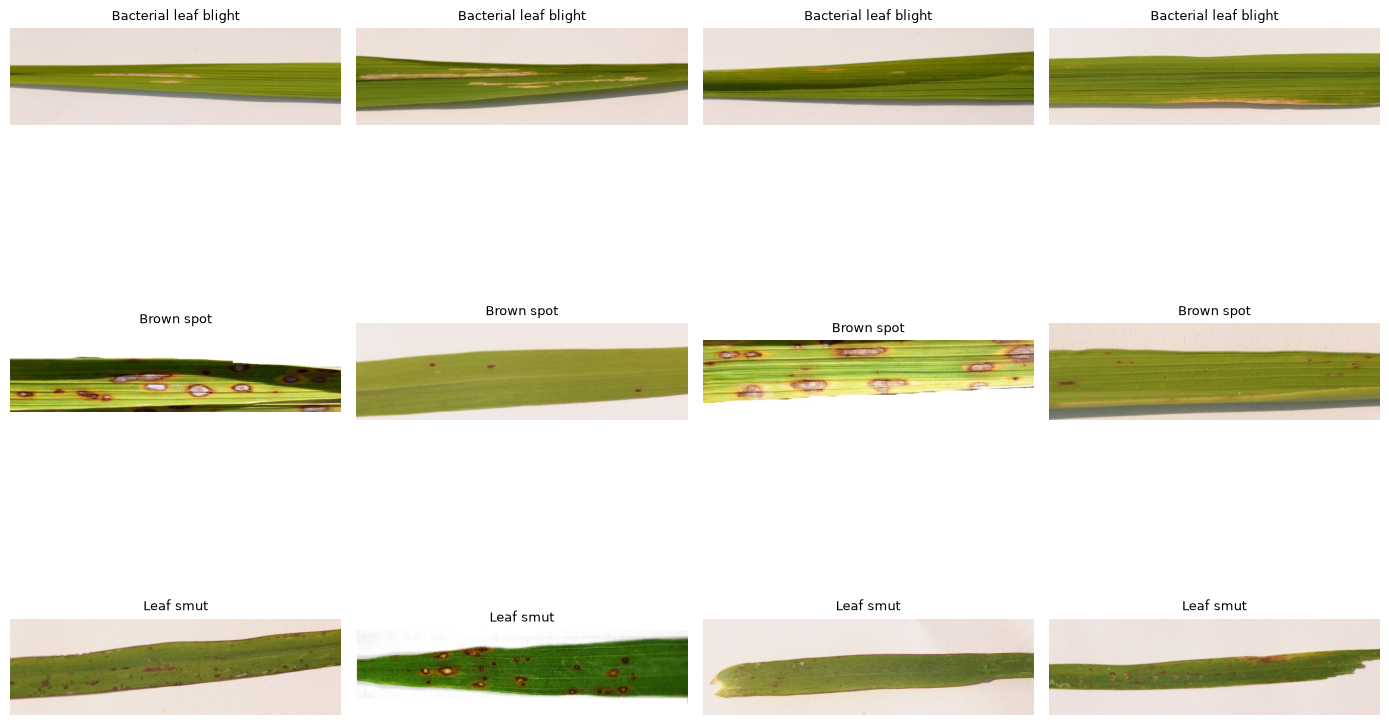

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

classes = df["label"].unique()
fig, axes = plt.subplots(len(classes), 4, figsize=(14, 3.5 * len(classes)))

for i, cls in enumerate(classes):
    samples = df[df["label"] == cls].sample(4, random_state=1)
    for j, path in enumerate(samples["path"]):
        axes[i, j].imshow(Image.open(path))
        axes[i, j].set_title(cls, fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [9]:
print(df["label"].value_counts())

label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64


In [10]:
for cls in df["label"].unique():
    all_files = []
    for root, dirs, files in os.walk(os.path.join("images", cls)):
        all_files += files
    exts = pd.Series([os.path.splitext(f)[1].lower() for f in all_files]).value_counts().to_dict()
    print(cls, "| total files:", len(all_files), "| by extension:", exts)

Bacterial leaf blight | total files: 40 | by extension: {'.jpg': 40}
Brown spot | total files: 40 | by extension: {'.jpg': 40}
Leaf smut | total files: 39 | by extension: {'.jpg': 39}


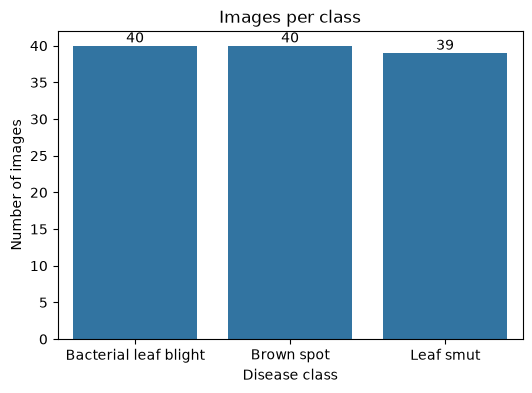

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="label")
ax.bar_label(ax.containers[0])
plt.title("Images per class")
plt.xlabel("Disease class")
plt.ylabel("Number of images")
plt.show()

In [12]:
from PIL import Image
import os

widths, heights, modes, sizes_kb = [], [], [], []
for p in df["path"]:
    with Image.open(p) as img:
        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)
    sizes_kb.append(os.path.getsize(p) / 1024)

df["width"] = widths
df["height"] = heights
df["mode"] = modes
df["size_kb"] = sizes_kb
df["aspect_ratio"] = df["width"] / df["height"]

print(df[["width", "height", "aspect_ratio", "size_kb"]].describe().round(1))
print("\nColor modes:", df["mode"].value_counts().to_dict())
print("\nUnique image sizes:", df.groupby(["width", "height"]).ngroups)

        width  height  aspect_ratio  size_kb
count   119.0   119.0         119.0    119.0
mean   2383.6   707.7           3.3    307.8
std    1123.5   311.7           0.6    172.7
min     250.0    71.0           1.2     22.8
25%    1074.0   377.0           3.4    102.7
50%    3081.0   897.0           3.4    379.4
75%    3081.0   897.0           3.4    426.9
max    3081.0   900.0           5.3    643.4

Color modes: {'RGB': 119}

Unique image sizes: 34


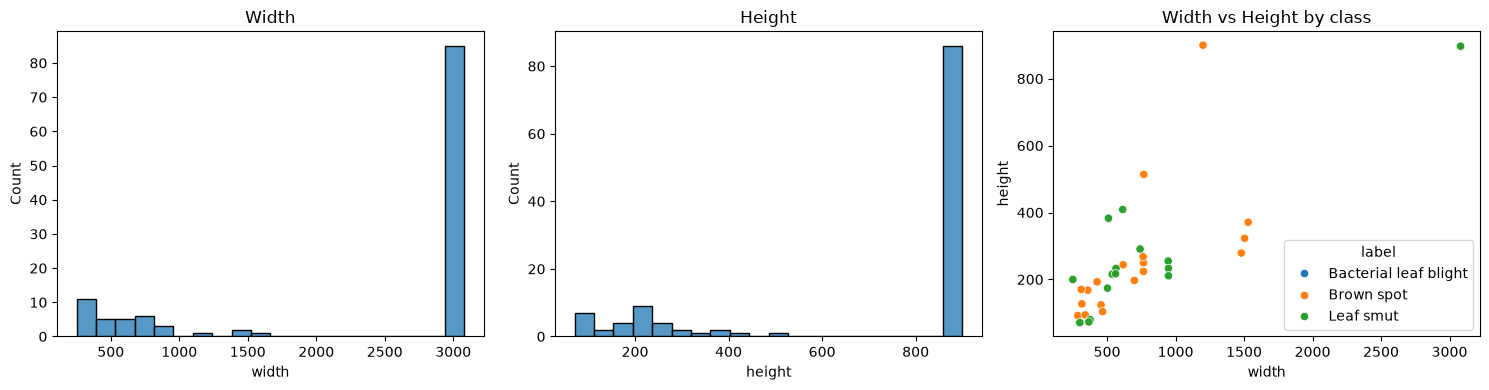

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["width"], ax=axes[0], bins=20); axes[0].set_title("Width")
sns.histplot(df["height"], ax=axes[1], bins=20); axes[1].set_title("Height")
sns.scatterplot(data=df, x="width", y="height", hue="label", ax=axes[2]); axes[2].set_title("Width vs Height by class")
plt.tight_layout()
plt.show()

In [14]:
summary = df.groupby("label").agg(
    images=("path", "count"),
    min_width=("width", "min"),
    max_width=("width", "max"),
    min_height=("height", "min"),
    max_height=("height", "max"),
    unique_sizes=("width", lambda s: df.loc[s.index].groupby(["width", "height"]).ngroups),
)
print(summary)

print("\nMost common size per class:")
for cls in df["label"].unique():
    top = df[df["label"] == cls].groupby(["width", "height"]).size().sort_values(ascending=False).head(1)
    print(cls, "->", top.index[0], "x", top.iloc[0], "images")

                       images  min_width  max_width  min_height  max_height  \
label                                                                         
Bacterial leaf blight      40       3081       3081         897         897   
Brown spot                 40        286       3081          88         900   
Leaf smut                  39        250       3081          71         897   

                       unique_sizes  
label                                
Bacterial leaf blight             1  
Brown spot                       20  
Leaf smut                        15  

Most common size per class:
Bacterial leaf blight -> (np.int64(3081), np.int64(897)) x 40 images
Brown spot -> (np.int64(3081), np.int64(897)) x 21 images
Leaf smut -> (np.int64(3081), np.int64(897)) x 24 images


In [15]:
df["is_standard"] = (df["width"] == 3081) & (df["height"] == 897)
print(pd.crosstab(df["label"], df["is_standard"], margins=True))

is_standard            False  True  All
label                                  
Bacterial leaf blight      0    40   40
Brown spot                19    21   40
Leaf smut                 15    24   39
All                       34    85  119


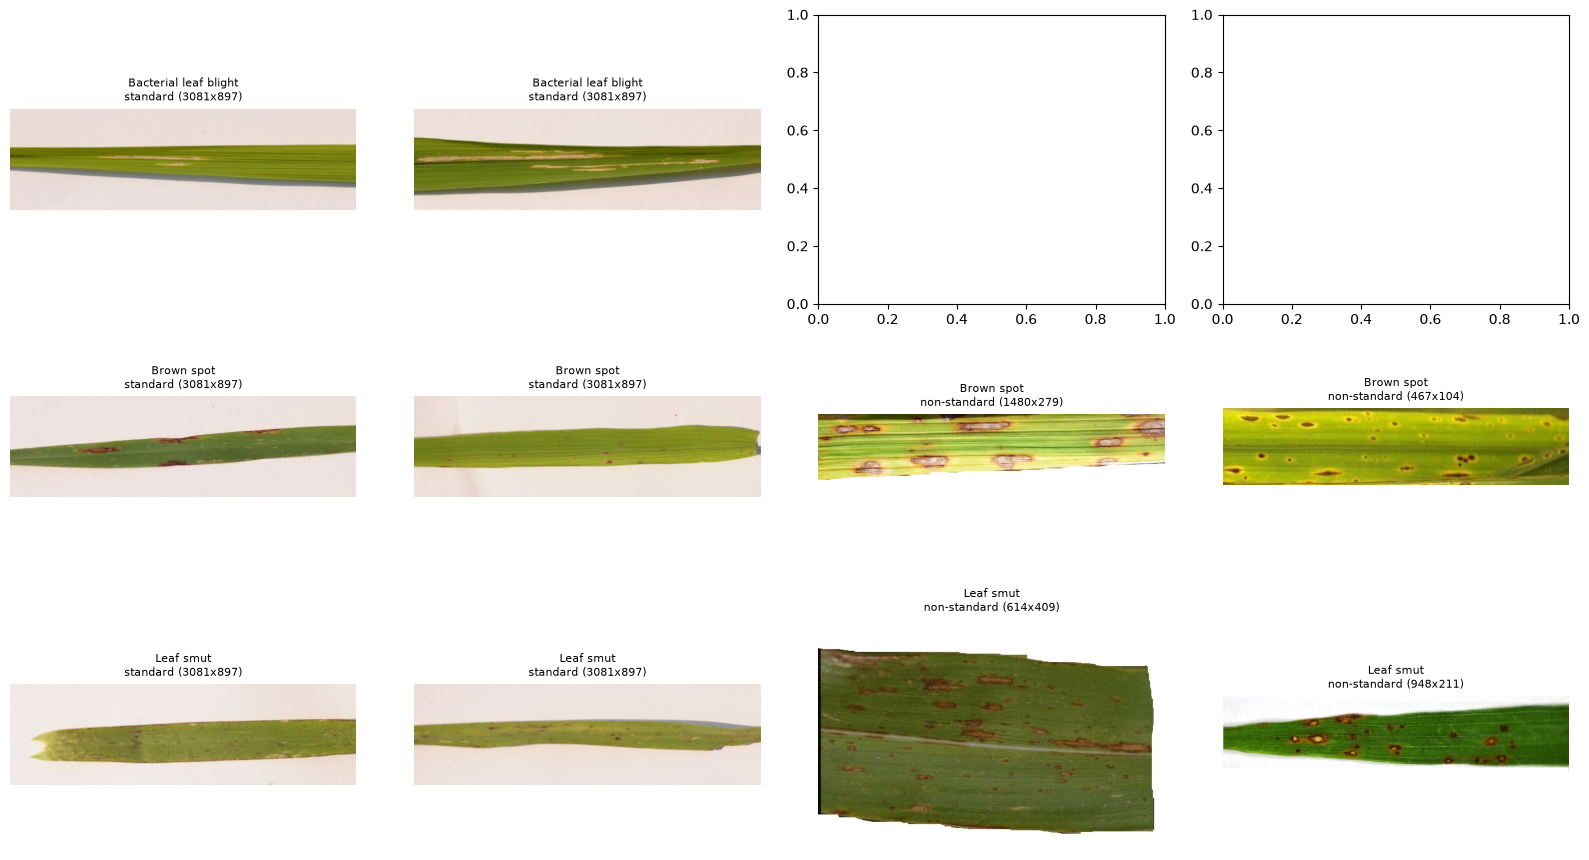

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))

for i, cls in enumerate(df["label"].unique()):
    sub = df[df["label"] == cls]
    std = sub[sub["is_standard"]].sample(2, random_state=1) if sub["is_standard"].sum() >= 2 else sub[sub["is_standard"]]
    non = sub[~sub["is_standard"]].sample(2, random_state=1) if (~sub["is_standard"]).sum() >= 2 else sub[~sub["is_standard"]]
    chosen = pd.concat([std, non])
    for j, (_, row) in enumerate(chosen.iterrows()):
        axes[i, j].imshow(Image.open(row["path"]))
        tag = "standard" if row["is_standard"] else "non-standard"
        axes[i, j].set_title(f"{cls}\n{tag} ({row['width']}x{row['height']})", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [17]:
import numpy as np

means = []
for p in df["path"]:
    arr = np.asarray(Image.open(p).convert("RGB").resize((128, 128)), dtype=np.float32)
    means.append(arr.reshape(-1, 3).mean(axis=0))
means = np.array(means)

df["mean_r"], df["mean_g"], df["mean_b"] = means[:, 0], means[:, 1], means[:, 2]
df["brightness"] = means.mean(axis=1)

print(df.groupby("label")[["mean_r", "mean_g", "mean_b", "brightness"]].mean().round(1))

                           mean_r      mean_g      mean_b  brightness
label                                                                
Bacterial leaf blight  194.199997  188.899994  152.199997  178.399994
Brown spot             191.300003  189.399994  126.699997  169.100006
Leaf smut              180.100006  181.899994  141.399994  167.800003


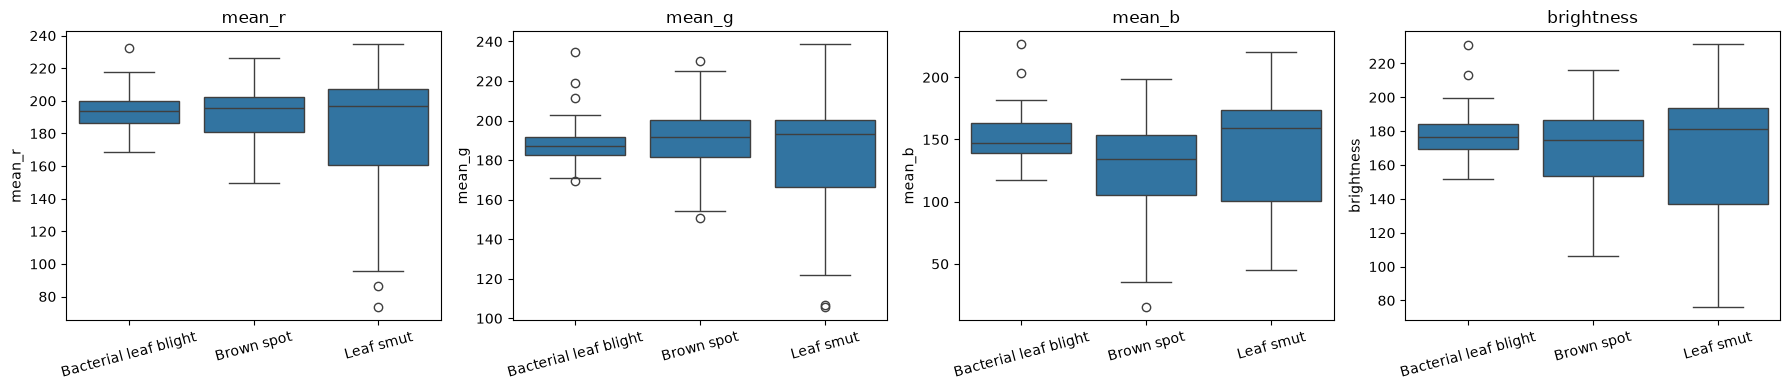

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["mean_r", "mean_g", "mean_b", "brightness"]):
    sns.boxplot(data=df, x="label", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

IMG_SIZE = 224

X = np.array([
    np.asarray(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
    for p in df["path"]
])

le = LabelEncoder()
y = le.fit_transform(df["label"])

print("X shape:", X.shape)
print("Pixel range:", X.min(), "to", X.max())
print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))

X shape: (119, 224, 224, 3)
Pixel range: 0.0 to 1.0
Classes: {'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}


In [20]:
from sklearn.model_selection import train_test_split

# Group key = disease class + whether the image is the standard 3081x897 size.
# Splitting on this makes sure every split gets a mix of image sizes, not just a mix of classes.
df["is_standard"] = (df["width"] == 3081) & (df["height"] == 897)
strat_key = df["label"] + "_" + df["is_standard"].astype(str)

idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=strat_key, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=strat_key.iloc[temp_idx], random_state=42)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
for name, ys in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, dict(zip(le.classes_, np.bincount(ys))))

Train: (83, 224, 224, 3) | Val: (18, 224, 224, 3) | Test: (18, 224, 224, 3)
Train {'Bacterial leaf blight': np.int64(28), 'Brown spot': np.int64(28), 'Leaf smut': np.int64(27)}
Val {'Bacterial leaf blight': np.int64(6), 'Brown spot': np.int64(6), 'Leaf smut': np.int64(6)}
Test {'Bacterial leaf blight': np.int64(6), 'Brown spot': np.int64(6), 'Leaf smut': np.int64(6)}


In [21]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

baseline = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax"),
], name="baseline_cnn")

baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,792,739 (10.65 MB)

 Trainable params: 2,792,739 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

history = baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 424ms/step - accuracy: 0.2771 - loss: 1.7647 - val_accuracy: 0.3333 - val_loss: 1.0840
Epoch 2/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.2289 - loss: 1.1233 - val_accuracy: 0.3333 - val_loss: 1.0832
Epoch 3/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - accuracy: 0.3494 - loss: 1.1070 - val_accuracy: 0.4444 - val_loss: 1.0238
Epoch 4/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.4819 - loss: 1.0100 - val_accuracy: 0.6111 - val_loss: 0.9631
Epoch 5/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 0.5783 - loss: 0.8991 - val_accuracy: 0.5556 - val_loss: 0.9022
Epoch 6/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.5060 - loss: 0.9351 - val_accuracy: 0.7222 - val_loss: 0.8093
Epoch 7/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.6024 - loss: 0.8809 - val_accuracy: 0.5556 - val_loss: 0.7803
Epoch 8/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.6988 - loss: 0.7250 - val_accuracy: 0.7778 - val_loss:

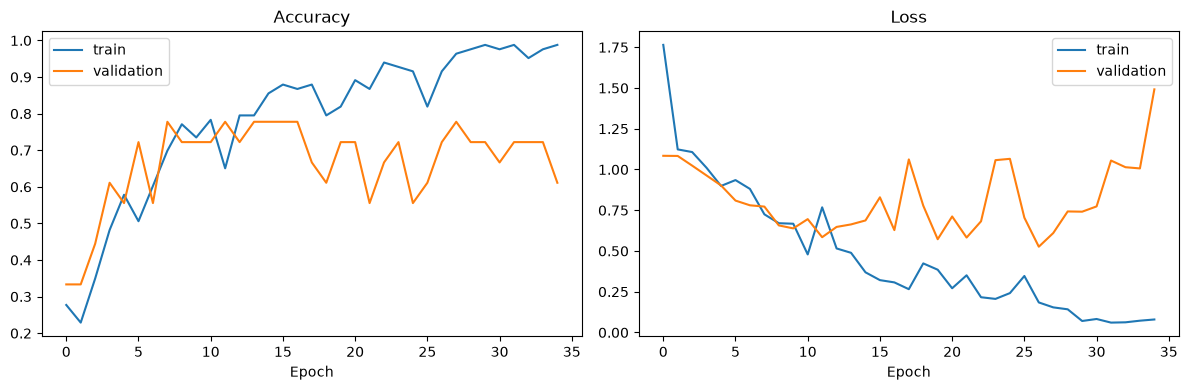

Best validation accuracy: 0.778


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

best = max(history.history["val_accuracy"])
print("Best validation accuracy:", round(best, 3))

In [7]:
for name in ["df", "X", "y", "le", "X_train", "X_val", "X_test", "baseline", "history"]:
    print(name, "->", "OK" if name in globals() else "MISSING")

df -> MISSING
X -> MISSING
y -> MISSING
le -> MISSING
X_train -> MISSING
X_val -> MISSING
X_test -> MISSING
baseline -> MISSING
history -> MISSING


In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# 1) Rebuild the image table from the extracted folders
rows = []
for cls in sorted(os.listdir("images")):
    cls_dir = os.path.join("images", cls)
    if os.path.isdir(cls_dir):
        for root, dirs, files in os.walk(cls_dir):
            for f in files:
                if f.lower().endswith((".jpg", ".jpeg", ".png")):
                    rows.append({"path": os.path.join(root, f), "label": cls})
df = pd.DataFrame(rows)

# 2) Record each image's size and whether it's the common 3081x897 size
sizes = [Image.open(p).size for p in df["path"]]
df["width"] = [s[0] for s in sizes]
df["height"] = [s[1] for s in sizes]
df["is_standard"] = (df["width"] == 3081) & (df["height"] == 897)

# 3) Load images resized to 224x224, pixels scaled to 0-1
IMG_SIZE = 224
X = np.array([
    np.asarray(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
    for p in df["path"]
])
le = LabelEncoder()
y = le.fit_transform(df["label"])

# 4) Stratified 70/15/15 split (class + image-size mix)
strat_key = df["label"] + "_" + df["is_standard"].astype(str)
idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=strat_key, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=strat_key.iloc[temp_idx], random_state=42)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Total images:", len(df), "| X shape:", X.shape)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
for name, ys in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, dict(zip(le.classes_, np.bincount(ys))))

Total images: 119 | X shape: (119, 224, 224, 3)
Train: (83, 224, 224, 3) | Val: (18, 224, 224, 3) | Test: (18, 224, 224, 3)
Train {'Bacterial leaf blight': np.int64(28), 'Brown spot': np.int64(28), 'Leaf smut': np.int64(27)}
Val {'Bacterial leaf blight': np.int64(6), 'Brown spot': np.int64(6), 'Leaf smut': np.int64(6)}
Test {'Bacterial leaf blight': np.int64(6), 'Brown spot': np.int64(6), 'Leaf smut': np.int64(6)}


Epoch 1/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 440ms/step - accuracy: 0.3133 - loss: 2.3866 - val_accuracy: 0.3333 - val_loss: 1.1204
Epoch 2/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.4217 - loss: 1.1518 - val_accuracy: 0.3889 - val_loss: 1.0984
Epoch 3/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.4699 - loss: 1.0511 - val_accuracy: 0.4444 - val_loss: 1.0680
Epoch 4/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - accuracy: 0.3976 - loss: 1.1171 - val_accuracy: 0.4444 - val_loss: 1.0307
Epoch 5/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.4819 - loss: 0.9769 - val_accuracy: 0.3889 - val_loss: 1.1302
Epoch 6/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - accuracy: 0.4217 - loss: 1.1083 - val_accuracy: 0.3889 - val_loss: 1.0226
Epoch 7/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.5663 - loss: 0.9319 - val_accuracy: 0.4444 - val_loss: 1.0767
Epoch 8/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 0.4578 - loss: 1.0386 - val_accuracy: 0.5000 - val_loss:

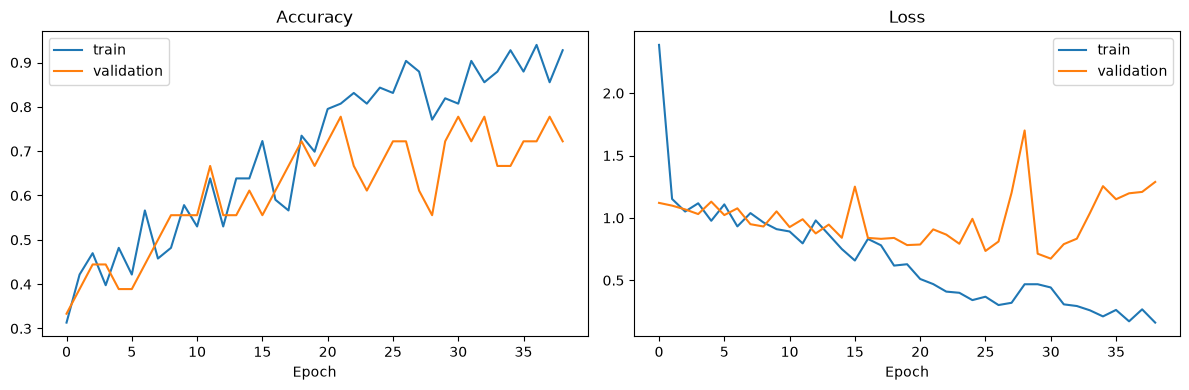

Best validation accuracy: 0.778
Baseline CNN (validation): accuracy = 0.778 | macro F1 = 0.784

                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      0.83      0.91         6
           Brown spot       0.80      0.67      0.73         6
            Leaf smut       0.62      0.83      0.71         6

             accuracy                           0.78        18
            macro avg       0.81      0.78      0.78        18
         weighted avg       0.81      0.78      0.78        18



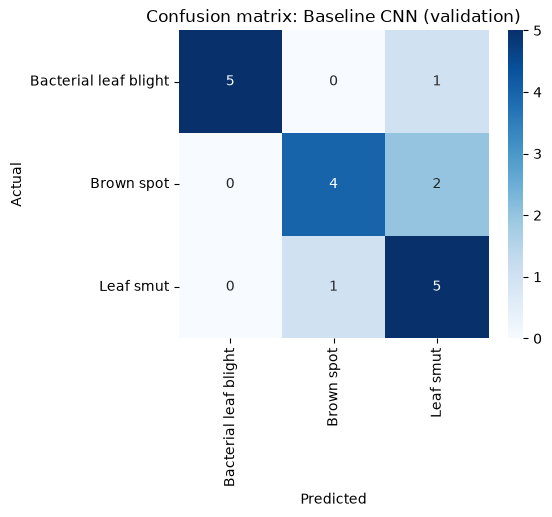

,Model,Val accuracy,Val macro F1
0,Baseline CNN,0.778,0.784


In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

tf.random.set_seed(42)
np.random.seed(42)

# ---- Step 8: build and train the baseline CNN ----
baseline = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax"),
], name="baseline_cnn")

baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
history = baseline.fit(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=40, batch_size=16, callbacks=[early_stop], verbose=1)

# ---- learning curves ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Best validation accuracy:", round(max(history.history["val_accuracy"]), 3))

# ---- Step 9: reusable evaluation function ----
def evaluate(y_true, y_pred, title="Model"):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{title}: accuracy = {acc:.3f} | macro F1 = {f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=le.classes_, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix: {title}")
    plt.show()
    return acc, f1

# ---- score on validation set and start the results table ----
val_pred = np.argmax(baseline.predict(X_val, verbose=0), axis=1)
base_acc, base_f1 = evaluate(y_val, val_pred, "Baseline CNN (validation)")

results = [{"Model": "Baseline CNN", "Val accuracy": round(base_acc, 3), "Val macro F1": round(base_f1, 3)}]
pd.DataFrame(results)

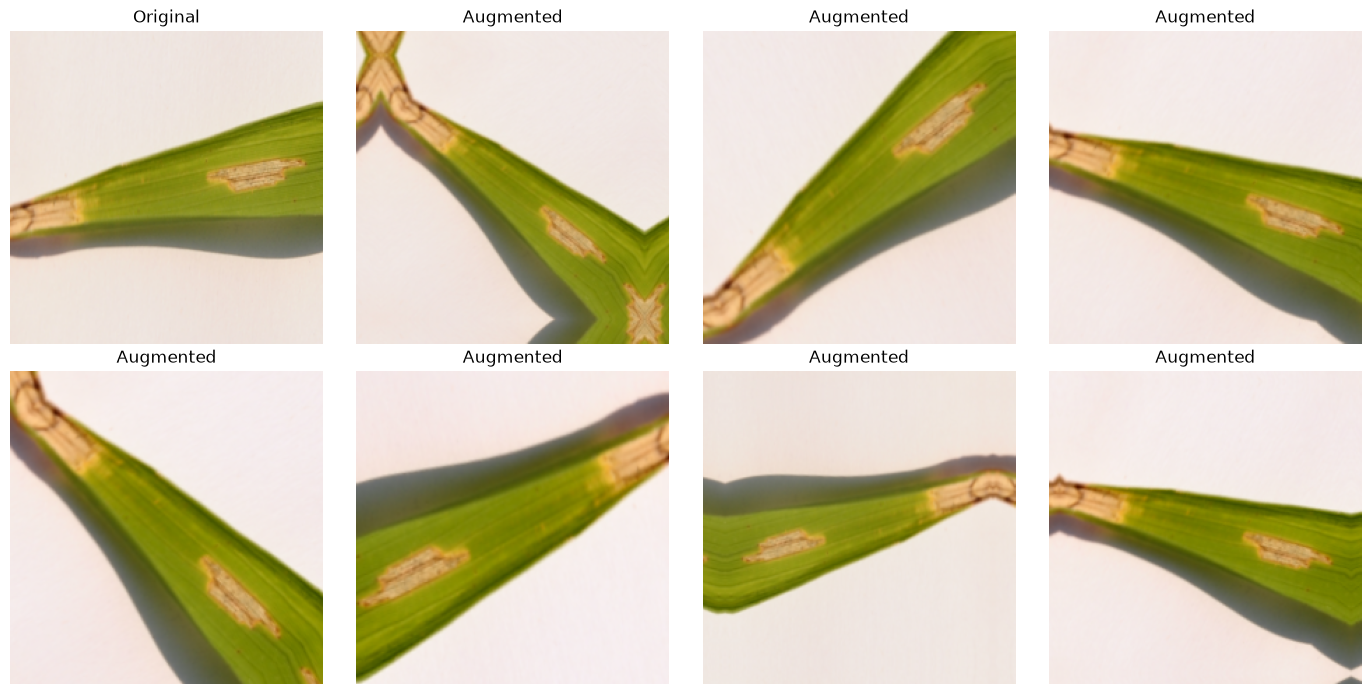

In [10]:
from tensorflow.keras import layers

preview_aug = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
])

sample = X_train[0:1]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(sample[0]); axes[0, 0].set_title("Original"); axes[0, 0].axis("off")
for ax in axes.flat[1:]:
    ax.imshow(np.clip(preview_aug(sample, training=True)[0], 0, 1))
    ax.set_title("Augmented"); ax.axis("off")
plt.tight_layout(); plt.show()

In [14]:
def build_cnn(aug_layers, name):
    model = keras.Sequential(
        [layers.Input(shape=(224, 224, 3))] + aug_layers + [
            layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
            layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
            layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(3, activation="softmax"),
        ], name=name)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [15]:
experiments = {
    "No augmentation": [],
    "Flip only": [layers.RandomFlip("horizontal_and_vertical")],
    "Flip + rotation": [layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15)],
    "Flip + rotation + zoom": [layers.RandomFlip("horizontal_and_vertical"),
                               layers.RandomRotation(0.15), layers.RandomZoom(0.2)],
    "Full (+ contrast)": [layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15),
                          layers.RandomZoom(0.2), layers.RandomContrast(0.2)],
}

aug_results, aug_models, aug_histories = [], {}, {}
for name, aug_layers in experiments.items():
    tf.random.set_seed(42); np.random.seed(42)
    model = build_cnn(aug_layers, name.replace(" ", "_").replace("+", "and").replace("(", "").replace(")", ""))
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=60, batch_size=16, callbacks=[stop], verbose=0)
    pred = np.argmax(model.predict(X_val, verbose=0), axis=1)
    aug_results.append({
        "Augmentation": name,
        "Train acc": round(h.history["accuracy"][-1], 3),
        "Val accuracy": round(accuracy_score(y_val, pred), 3),
        "Val macro F1": round(f1_score(y_val, pred, average="macro"), 3),
        "Epochs run": len(h.history["loss"]),
    })
    aug_models[name], aug_histories[name] = model, h
    print("done:", name)

aug_df = pd.DataFrame(aug_results)
aug_df

done: No augmentation
done: Flip only
done: Flip + rotation
done: Flip + rotation + zoom
done: Full (+ contrast)


,Augmentation,Train acc,Val accuracy,Val macro F1,Epochs run
0,No augmentation,0.892,0.722,0.716,24
1,Flip only,0.880,0.778,0.764,32
2,Flip + rotation,0.807,0.722,0.713,60
3,Flip + rotation + zoom,0.819,0.778,0.738,52
4,Full (+ contrast),0.807,0.722,0.690,50


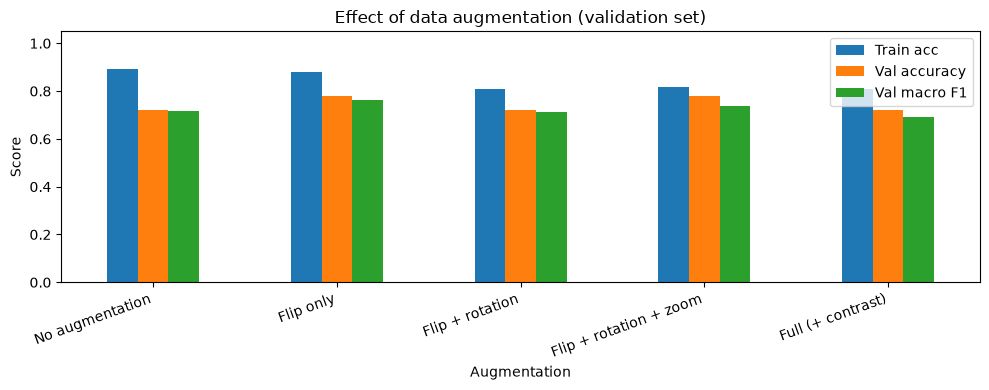

In [16]:
aug_df.set_index("Augmentation")[["Train acc", "Val accuracy", "Val macro F1"]].plot(
    kind="bar", figsize=(10, 4))
plt.title("Effect of data augmentation (validation set)")
plt.ylabel("Score"); plt.ylim(0, 1.05); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

In [17]:
from tensorflow.keras.applications import MobileNetV2

tf.random.set_seed(42); np.random.seed(42)

base = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False   # freeze: keep its learned knowledge as is

mobilenet = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.Rescaling(2.0, offset=-1.0),        # 0-1  ->  -1 to 1 (what MobileNetV2 expects)
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax"),
], name="mobilenetv2_transfer")

mobilenet.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mobilenet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_9 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_7               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_5 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
hist_mn = mobilenet.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=40, batch_size=16, callbacks=[stop], verbose=1)

Epoch 1/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.2892 - loss: 1.5804 - val_accuracy: 0.6111 - val_loss: 1.0976
Epoch 2/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 259ms/step - accuracy: 0.4096 - loss: 1.1915 - val_accuracy: 0.6667 - val_loss: 0.8258
Epoch 3/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step - accuracy: 0.6627 - loss: 0.8790 - val_accuracy: 0.7778 - val_loss: 0.6087
Epoch 4/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 248ms/step - accuracy: 0.7711 - loss: 0.6089 - val_accuracy: 0.9444 - val_loss: 0.5128
Epoch 5/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 270ms/step - accuracy: 0.8313 - loss: 0.4624 - val_accuracy: 0.9444 - val_loss: 0.4555
Epoch 6/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 279ms/step - accuracy: 0.7952 - loss: 0.4883 - val_accuracy: 0.9444 - val_loss: 0.4178
Epoch 7/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 282ms/step - accuracy: 0.8313 - loss: 0.3827 - val_accuracy: 0.9444 - val_loss: 0.4011
Epoch 8/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - accuracy: 0.9157 - loss: 0.3082 - val_accuracy: 0.9444 - val_loss: 0

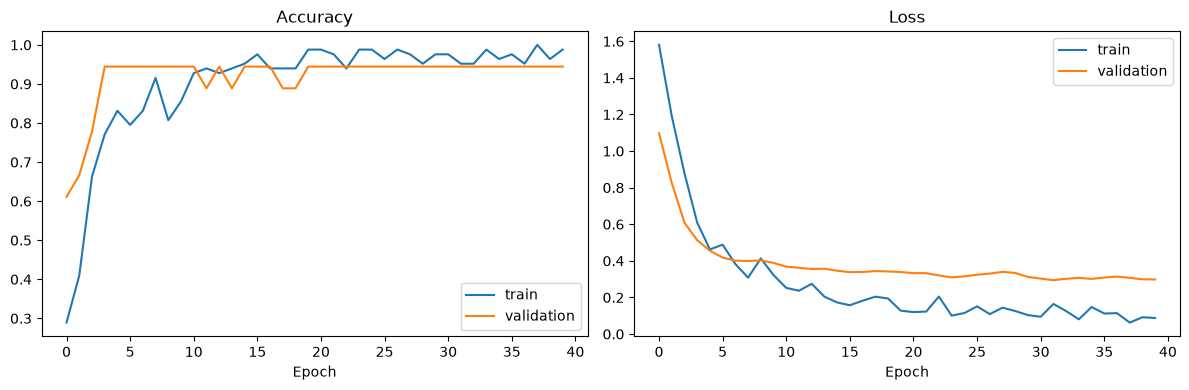

MobileNetV2 transfer (validation): accuracy = 0.944 | macro F1 = 0.944

                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      0.83      0.91         6
           Brown spot       0.86      1.00      0.92         6
            Leaf smut       1.00      1.00      1.00         6

             accuracy                           0.94        18
            macro avg       0.95      0.94      0.94        18
         weighted avg       0.95      0.94      0.94        18



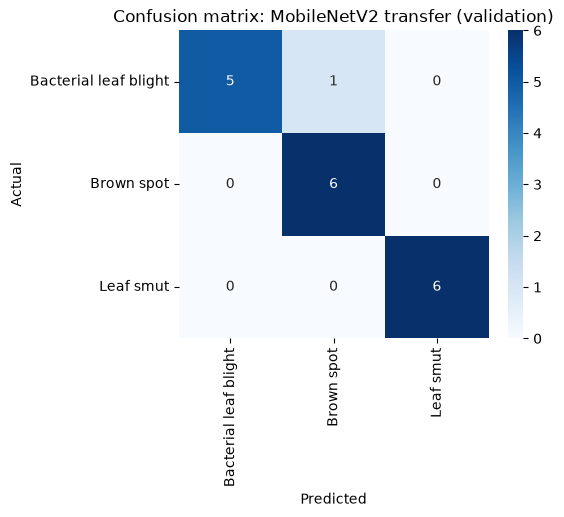

,Model,Val accuracy,Val macro F1
0,Baseline CNN,0.778,0.784
1,MobileNetV2 (frozen),0.944,0.944


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_mn.history["accuracy"], label="train")
axes[0].plot(hist_mn.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist_mn.history["loss"], label="train")
axes[1].plot(hist_mn.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

mn_pred = np.argmax(mobilenet.predict(X_val, verbose=0), axis=1)
mn_acc, mn_f1 = evaluate(y_val, mn_pred, "MobileNetV2 transfer (validation)")

results.append({"Model": "MobileNetV2 (frozen)", "Val accuracy": round(mn_acc, 3), "Val macro F1": round(mn_f1, 3)})
pd.DataFrame(results)

In [20]:
import cv2

def color_hist_features(img01, bins=8):
    """img01: float image 0-1 -> HSV color histogram (bins^3 numbers) + mean/std per channel."""
    img8 = (img01 * 255).astype(np.uint8)
    hsv = cv2.cvtColor(img8, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [bins] * 3, [0, 180, 0, 256, 0, 256]).flatten()
    hist = hist / hist.sum()                       # proportions, so image size doesn't matter
    stats = np.concatenate([img01.reshape(-1, 3).mean(axis=0), img01.reshape(-1, 3).std(axis=0)])
    return np.concatenate([hist, stats])

F_train = np.array([color_hist_features(im) for im in X_train])
F_val   = np.array([color_hist_features(im) for im in X_val])
print("Feature shape:", F_train.shape)

Feature shape: (83, 518)


In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

classical = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, random_state=42)),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42),
    "KNN (k=5)":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

fitted = {}
for name, model in classical.items():
    model.fit(F_train, y_train)
    pred = model.predict(F_val)
    acc, f1 = accuracy_score(y_val, pred), f1_score(y_val, pred, average="macro")
    results.append({"Model": name, "Val accuracy": round(acc, 3), "Val macro F1": round(f1, 3)})
    fitted[name] = model

pd.DataFrame(results)

,Model,Val accuracy,Val macro F1
0,Baseline CNN,0.778,0.784
1,MobileNetV2 (frozen),0.944,0.944
2,Logistic Regression,0.889,0.882
3,SVM (RBF),0.778,0.783
4,Random Forest,0.944,0.944
5,KNN (k=5),0.833,0.836


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

F_all = np.vstack([F_train, F_val])
y_all = np.concatenate([y_train, y_val])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in classical.items():
    scores = cross_val_score(model, F_all, y_all, cv=skf, scoring="accuracy")
    cv_rows.append({"Model": name, "CV mean acc": round(scores.mean(), 3), "CV std": round(scores.std(), 3)})
pd.DataFrame(cv_rows)

,Model,CV mean acc,CV std
0,Logistic Regression,0.822,0.079
1,SVM (RBF),0.782,0.041
2,Random Forest,0.853,0.079
3,KNN (k=5),0.813,0.094


In [23]:
import time

# Features for the classical models
F_test = np.array([color_hist_features(im) for im in X_test])

# The best augmentation setup from Step 10, picked using validation scores only
best_aug_name = aug_df.sort_values(["Val macro F1", "Val accuracy"], ascending=False).iloc[0]["Augmentation"]
print("Best augmentation setup (by validation):", best_aug_name)

cnn_models = {
    "Baseline CNN": baseline,
    f"CNN + aug ({best_aug_name})": aug_models[best_aug_name],
    "MobileNetV2 (frozen)": mobilenet,
}

test_rows, test_preds = [], {}

for name, m in cnn_models.items():
    t0 = time.time()
    pred = np.argmax(m.predict(X_test, verbose=0), axis=1)
    ms = (time.time() - t0) / len(X_test) * 1000
    test_preds[name] = pred
    test_rows.append({"Model": name,
                      "Test accuracy": round(accuracy_score(y_test, pred), 3),
                      "Test macro F1": round(f1_score(y_test, pred, average="macro"), 3),
                      "ms / image": round(ms, 1)})

for name, m in fitted.items():
    t0 = time.time()
    pred = m.predict(F_test)
    ms = (time.time() - t0) / len(X_test) * 1000
    test_preds[name] = pred
    test_rows.append({"Model": name,
                      "Test accuracy": round(accuracy_score(y_test, pred), 3),
                      "Test macro F1": round(f1_score(y_test, pred, average="macro"), 3),
                      "ms / image": round(ms, 1)})

test_df = pd.DataFrame(test_rows).sort_values("Test macro F1", ascending=False).reset_index(drop=True)
test_df

Best augmentation setup (by validation): Flip only


,Model,Test accuracy,Test macro F1,ms / image
0,MobileNetV2 (frozen),0.833,0.831,26.0
1,SVM (RBF),0.778,0.771,0.2
2,Random Forest,0.722,0.720,5.1
3,KNN (k=5),0.667,0.665,0.7
4,Baseline CNN,0.667,0.659,19.1
5,Logistic Regression,0.667,0.641,0.1
6,CNN + aug (Flip only),0.611,0.595,10.2


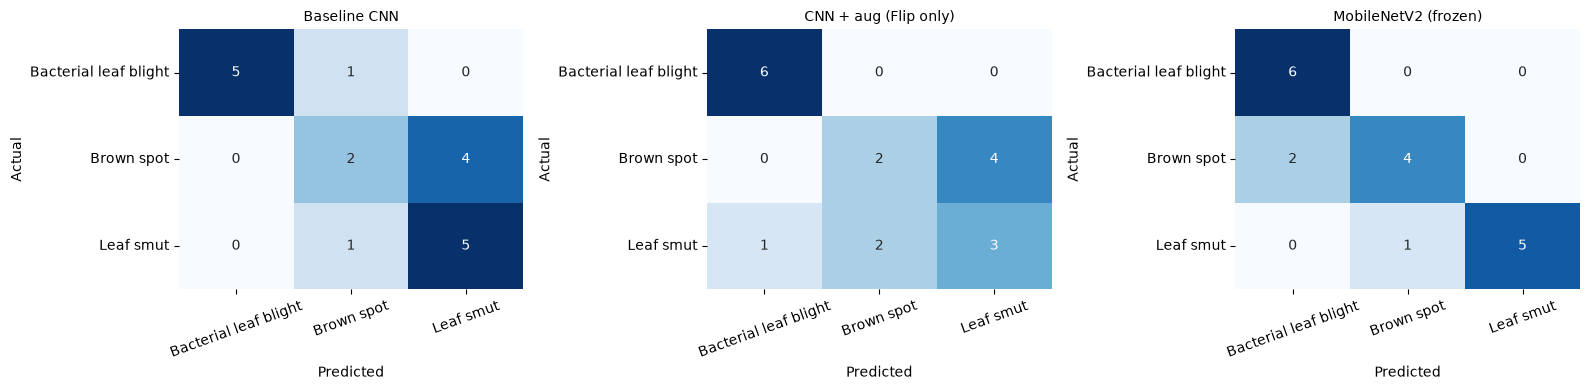

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, cnn_models.items()):
    cm = confusion_matrix(y_test, test_preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

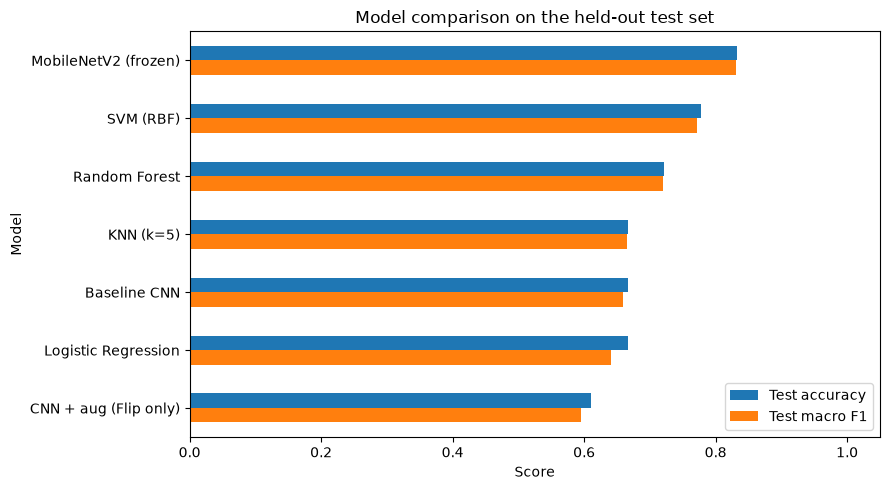

In [25]:
plot_df = test_df.set_index("Model")[["Test accuracy", "Test macro F1"]]
plot_df.plot(kind="barh", figsize=(9, 5))
plt.title("Model comparison on the held-out test set")
plt.xlabel("Score"); plt.xlim(0, 1.05)
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

In [ ]:
# Task 1: Data Analysis Report

**Dataset:** [119] images of rice leaves in 3 classes: Bacterial leaf blight ([40]), Brown spot ([40]), Leaf smut ([39]). Classes are almost perfectly balanced.

**Image sizes:** The images have [34] different sizes. About [85] images are 3081 x 897; the rest range from about 250 x 71 up to 3081 x 897. All [40] Bacterial leaf blight images are 3081 x 897, while Brown spot and Leaf smut mix large and small images.

**Colour/brightness:** [Which class differs most, in which channel, from your box plots. Say whether the boxes overlap.]

**Key findings:**
1. Classes are balanced, so accuracy is a fair metric (we also report macro F1).
2. Image size is partly correlated with class, a potential shortcut for a model.
3. [Your colour finding.]
4. The dataset is very small, so overfitting is the main risk.

In [ ]:
# Task 3: Data Augmentation Report

**Why:** Only 83 training images, so the CNN tends to memorise them. Augmentation creates random flipped, rotated, zoomed and contrast-shifted variants each epoch (training only).

**Experiment:** The same CNN was trained 5 times with different augmentation, same seed, same split.

[Paste your Step 10 table here as a markdown table]

**Observations:**
- Without augmentation, train accuracy was [x] vs validation [y] (gap = [z]), indicating [overfitting / not].
- The best setup was [name] with validation macro F1 of [x].
- [Did adding more augmentation always help? Say honestly if not.]

**Caveat:** The validation set has 18 images, so one image is about 5.5%. Differences smaller than that may be noise.

In [ ]:
# Model Comparison Report

[Paste your test results table: Model, Test accuracy, Test macro F1, ms/image]

**Cross-validation (classical models):** [paste CV table]

**Findings:**
- Best on the test set: [model] ([acc], [F1]).
- Classical models using colour features reached [x], [better/worse] than the CNNs, because colour alone [does/doesn't] capture lesion shape and texture.
- Most common confusion: [class A] vs [class B].

**Recommendation for production:** [model], because [test score, stability in CV, speed per image, small size, handles variation in image size]. Models within about 1 test image of each other are effectively tied.

**Limitations:** Only 119 photos, an 18-image test set, and the image-size bias; a larger and more varied dataset is needed before real-world use.

In [ ]:
# Report on Challenges Faced
| Dataset delivered as 3 zip files with dated names | Class folders did not exist after the first unzip | Unzipped each file into its own class folder and cleaned the name for the label | Needed labels from folder names |
| Class count 39 vs 40 | Leaf smut has 39 images | Verified file counts; used macro F1 | A 1-image gap is negligible but should be reported |
| Very different image sizes | 34 sizes; Bacterial blight is always 3081x897 | Resized all to 224x224; stratified the split by class + size group | Removes the raw-size shortcut and keeps every split mixed |
| Very small dataset | 83 training images | Data augmentation, Dropout, transfer learning (MobileNetV2) | Reduce overfitting and reuse learned features |
| Overfitting risk | [train vs val gap] | Early stopping with best-weights restore | Stops training before memorisation |
| Unreliable scores | 18 val/test images, 1 image = 5.5% | Macro F1, 5-fold cross-validation, test set used once | Steadier, more honest estimates |
| [Any other issue you actually hit, e.g. kernel restart, TensorFlow install, warnings] | 